# Map data to a normal distribution: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/preprocessing/plot_map_data_to_normal.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/preprocessing/plot_map_data_to_normal.html)).

**Scenario:** six 1-D distributions (lognormal, chi-squared, Weibull, Gaussian, uniform, bimodal) are split in
halves; `PowerTransformer(method="box-cox")`, `PowerTransformer(method="yeo-johnson")` and
`QuantileTransformer(n_quantiles=500, output_distribution="normal")` are fitted on the training half and transform
the test half. The same three estimator objects are refitted for every distribution.

**Adaptations:**
- The example calls `train_test_split(X, test_size=0.5)` without a seed, i.e. from NumPy's global stream, so
  its splits are not reproducible. Here every split uses `random_state=k` for distribution `k` (0..5); the data
  themselves come from the example's `RandomState(304)` unchanged. The splits are shared with Moxie.
- The example passes `random_state=rng` (a `RandomState` instance) to `QuantileTransformer`. With at most 1000
  training rows and `subsample=10_000` no subsample is drawn, so the generator is never consulted; Moxie uses its
  `random_state=None` default, which likewise draws nothing.
- Beyond the example, Moxie also returns `inverse_transform` of each transformed test half, compared against
  scikit-learn's.
- Histograms are drawn at dpi 60; the Moxie histograms are overlaid on the reference ones.

**Determinism:** deterministic once the splits are seeded. Lambdas come from a bounded Brent search on a
log-likelihood that is flat near its optimum, so final-ulp differences in the objective can move the optimum within
the optimizer's tolerance (see the tolerances below and `families/preprocessing/docs/api/quantiles.md`).

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
# The reference is the pinned scikit-learn source (an overlay of the pinned Python
# sources on the installed wheel's compiled extensions), not the installed 1.9.1 wheel.
sys.path.insert(0, str(ROOT / "families/preprocessing/tests/parity"))
import overlay
sklearn = overlay.activate()
print("reference scikit-learn", sklearn.__version__, "from", Path(sklearn.__file__).parent)
%load_ext moxie_nb
nb = moxie_nb.Session("preprocessing/plot_map_data_to_normal")

reference scikit-learn 1.10.dev0 from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/families/preprocessing/builds/oracle/sklearn


## 1. scikit-learn (Python reference)

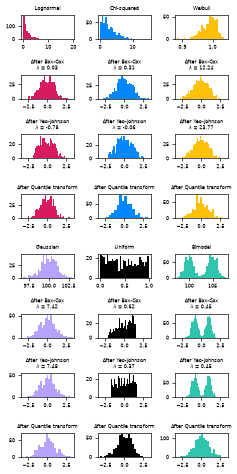

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

N_SAMPLES = 1000
FONT_SIZE = 6
BINS = 30


rng = np.random.RandomState(304)
bc = PowerTransformer(method="box-cox")
yj = PowerTransformer(method="yeo-johnson")
# n_quantiles is set to the training set size rather than the default value
# to avoid a warning being raised by this example
qt = QuantileTransformer(
    n_quantiles=500, output_distribution="normal", random_state=rng
)
size = (N_SAMPLES, 1)


# lognormal distribution
X_lognormal = rng.lognormal(size=size)

# chi-squared distribution
df = 3
X_chisq = rng.chisquare(df=df, size=size)

# weibull distribution
a = 50
X_weibull = rng.weibull(a=a, size=size)

# gaussian distribution
loc = 100
X_gaussian = rng.normal(loc=loc, size=size)

# uniform distribution
X_uniform = rng.uniform(low=0, high=1, size=size)

# bimodal distribution
loc_a, loc_b = 100, 105
X_a, X_b = rng.normal(loc=loc_a, size=size), rng.normal(loc=loc_b, size=size)
X_bimodal = np.concatenate([X_a, X_b], axis=0)


# create plots
distributions = [
    ("Lognormal", X_lognormal),
    ("Chi-squared", X_chisq),
    ("Weibull", X_weibull),
    ("Gaussian", X_gaussian),
    ("Uniform", X_uniform),
    ("Bimodal", X_bimodal),
]

colors = ["#D81B60", "#0188FF", "#FFC107", "#B7A2FF", "#000000", "#2EC5AC"]

fig, axes = plt.subplots(nrows=8, ncols=3, figsize=plt.figaspect(2), dpi=60)
axes = axes.flatten()
axes_idxs = [
    (0, 3, 6, 9),
    (1, 4, 7, 10),
    (2, 5, 8, 11),
    (12, 15, 18, 21),
    (13, 16, 19, 22),
    (14, 17, 20, 23),
]
axes_list = [(axes[i], axes[j], axes[k], axes[l]) for (i, j, k, l) in axes_idxs]

sk = []
shared = {}
for k, (distribution, color, axes) in enumerate(zip(distributions, colors, axes_list)):
    name, X = distribution
    X_train, X_test = train_test_split(X, test_size=0.5, random_state=k)  # adaptation: seeded split
    shared[f"train{k}"], shared[f"test{k}"] = X_train, X_test

    # perform power transforms and quantile transform
    X_trans_bc = bc.fit(X_train).transform(X_test)
    lmbda_bc = round(bc.lambdas_[0], 2)
    X_trans_yj = yj.fit(X_train).transform(X_test)
    lmbda_yj = round(yj.lambdas_[0], 2)
    X_trans_qt = qt.fit(X_train).transform(X_test)
    sk.append(dict(bc=X_trans_bc, yj=X_trans_yj, qt=X_trans_qt,
                   bc_lambda=bc.lambdas_.copy(), yj_lambda=yj.lambdas_.copy(),
                   quantiles=qt.quantiles_.copy(), references=qt.references_.copy(),
                   bc_inv=bc.inverse_transform(X_trans_bc), yj_inv=yj.inverse_transform(X_trans_yj),
                   qt_inv=qt.inverse_transform(X_trans_qt)))

    ax_original, ax_bc, ax_yj, ax_qt = axes

    ax_original.hist(X_train, color=color, bins=BINS)
    ax_original.set_title(name, fontsize=FONT_SIZE)
    ax_original.tick_params(axis="both", which="major", labelsize=FONT_SIZE)

    for ax, X_trans, meth_name, lmbda in zip(
        (ax_bc, ax_yj, ax_qt),
        (X_trans_bc, X_trans_yj, X_trans_qt),
        ("Box-Cox", "Yeo-Johnson", "Quantile transform"),
        (lmbda_bc, lmbda_yj, None),
    ):
        ax.hist(X_trans, color=color, bins=BINS)
        title = "After {}".format(meth_name)
        if lmbda is not None:
            title += "\n$\\lambda$ = {}".format(lmbda)
        ax.set_title(title, fontsize=FONT_SIZE)
        ax.tick_params(axis="both", which="major", labelsize=FONT_SIZE)
        ax.set_xlim([-3.5, 3.5])


plt.tight_layout()
plt.show()
nb.share(**shared)

## 2. Moxie (native Mojo)

The same three estimator objects, refitted on each training half.

In [3]:
%%mojo map_to_normal
from moxie.preprocessing import PowerTransformer, QuantileTransformer
from moxie_nb_io import load, save


def main() raises:
    var bc = PowerTransformer(method="box-cox")
    var yj = PowerTransformer(method="yeo-johnson")
    var qt = QuantileTransformer(n_quantiles=500, output_distribution="normal")
    for k in range(6):
        var X_train = load("train" + String(k))
        var X_test = load("test" + String(k))
        var tag = String(k)
        var X_trans_bc = bc.fit(X_train).transform(X_test)
        var X_trans_yj = yj.fit(X_train).transform(X_test)
        var X_trans_qt = qt.fit(X_train).transform(X_test)
        save("bc" + tag, X_trans_bc)
        save("yj" + tag, X_trans_yj)
        save("qt" + tag, X_trans_qt)
        save("bc_lambda" + tag, bc.lambdas_)
        save("yj_lambda" + tag, yj.lambdas_)
        save("quantiles" + tag, qt.quantiles_)
        save("references" + tag, qt.references_)
        save("bc_inv" + tag, bc.inverse_transform(X_trans_bc))
        save("yj_inv" + tag, yj.inverse_transform(X_trans_yj))
        save("qt_inv" + tag, qt.inverse_transform(X_trans_qt))
        print(tag, "box-cox lambda", bc.lambdas_.item(0), "yeo-johnson lambda", yj.lambdas_.item(0))

0 box-cox lambda 0.028533058862907777 yeo-johnson lambda -0.781481397322053
1 box-cox lambda 0.3099063685775213 yeo-johnson lambda -0.061550736121502005
2 box-cox lambda 12.235662841403014 yeo-johnson lambda 23.77284481981278
3 box-cox lambda 7.416249784290151 yeo-johnson lambda 7.480452616899253
4 box-cox lambda 0.619826864663192 yeo-johnson lambda 0.36960652957707746
5 box-cox lambda 0.44907459525633797 yeo-johnson lambda 0.4478474728624987


## 3. Side by side and parity

Tolerances (from `families/preprocessing/docs/api/quantiles.md`, where they are derived and measured):
- `lambdas_`: rtol 2e-7, atol `max(2e-7, 2 * sqrt(eps * |llf| / curvature))`. Brent/`fminbound` stop within
  `xtol = 1.48e-8` (relative) of the optimum, and the log-likelihood is flat there, so one-ulp differences in the
  objective can move the stopping point by roughly `sqrt(eps * |llf| / curvature)`. That width depends on the
  data: it is about 1e-7 for the family parity inputs but 7e-7 for the bimodal sample here (values near 100 with a
  small spread, so the likelihood curvature in lambda is only about 0.4). A second check confirms that SciPy's own
  log-likelihood at Moxie's lambda equals its value at sklearn's lambda to within the objective's spread over that
  flat region (around 1e-12, dominated by summation rounding), i.e. both are equally good optima.
- Power-transformed values: rtol/atol 1e-6, the lambda tolerance propagated through `d transform / d lambda`
  and the standardization.
- Inverse power transforms: rtol 1e-6 on the reconstructed data (same propagation, inverted).
- `quantiles_`, `references_`: exact (same `nanpercentile`/`linspace` arithmetic on the same rows).
- Quantile transforms and inverses: rtol 1e-12, atol 1e-15 (the interpolation and Cephes `ndtri`/`ndtr` are
  replayed operation by operation; only final-bit rounding can differ).

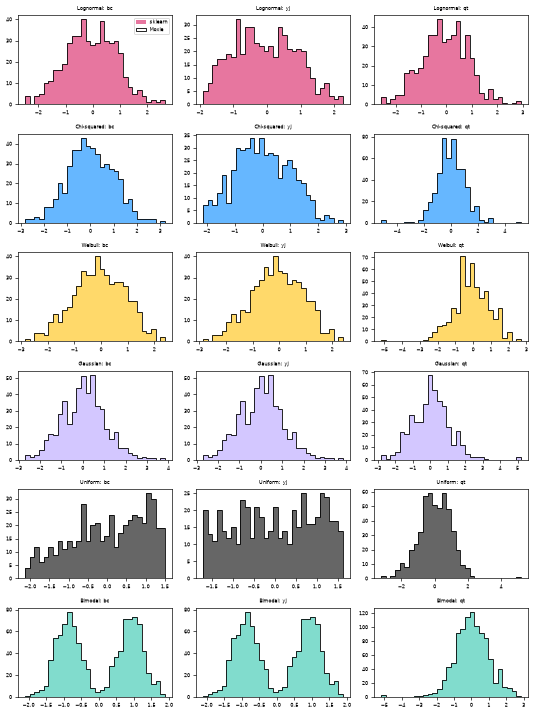

,distribution,sklearn box-cox,Moxie box-cox,sklearn yeo-johnson,Moxie yeo-johnson
0,Lognormal,0.028533,0.028533,-0.781481,-0.781481
1,Chi-squared,0.309906,0.309906,-0.061551,-0.061551
2,Weibull,12.235663,12.235663,23.772843,23.772845
3,Gaussian,7.416250,7.416250,7.480453,7.480453
4,Uniform,0.619827,0.619827,0.369607,0.369607
5,Bimodal,0.449075,0.449075,0.447848,0.447847


In [4]:
mx = nb.results["map_to_normal"]

fig, axes = plt.subplots(6, 3, figsize=(9, 12), dpi=60)
for k, (name, _) in enumerate(distributions):
    for m, method in enumerate(["bc", "yj", "qt"]):
        ax = axes[k, m]
        ax.hist(sk[k][method], bins=BINS, color=colors[k], alpha=0.6, label="sklearn")
        ax.hist(mx[method + str(k)], bins=BINS, histtype="step", color="k", label="Moxie")
        ax.set_title(f"{name}: {method}", fontsize=FONT_SIZE)
        ax.tick_params(labelsize=FONT_SIZE)
axes[0, 0].legend(fontsize=FONT_SIZE)
plt.tight_layout()
plt.show()

import pandas as pd
moxie_nb.side_by_side(lambdas=pd.DataFrame({
    "distribution": [d[0] for d in distributions],
    "sklearn box-cox": [sk[k]["bc_lambda"][0] for k in range(6)],
    "Moxie box-cox": [mx[f"bc_lambda{k}"][0] for k in range(6)],
    "sklearn yeo-johnson": [sk[k]["yj_lambda"][0] for k in range(6)],
    "Moxie yeo-johnson": [mx[f"yj_lambda{k}"][0] for k in range(6)],
}))

from scipy import stats

EPS = np.finfo(np.float64).eps
LLF = {"bc": stats.boxcox_llf, "yj": stats.yeojohnson_llf}


def flat_width(llf, lam, x):
    """sqrt(eps * |llf| / curvature): how far rounding noise lets Brent wander from the optimum."""
    h = 1e-3
    curvature = (llf(lam + h, x) - 2 * llf(lam, x) + llf(lam - h, x)) / h ** 2
    return float(np.sqrt(EPS * abs(llf(lam, x)) / abs(curvature)))


for k, (name, _) in enumerate(distributions):
    x_train = shared[f"train{k}"][:, 0]
    for method, label in [("bc", "box-cox"), ("yj", "yeo-johnson")]:
        llf = LLF[method]
        sk_lambda, mx_lambda = sk[k][method + "_lambda"], mx[f"{method}_lambda{k}"]
        width = flat_width(llf, sk_lambda[0], x_train)
        nb.compare(f"{name}: {label} lambdas_", sk_lambda, mx_lambda, rtol=2e-7, atol=max(2e-7, 2 * width),
                   reason=f"Brent stops within xtol on a flat log-likelihood; atol = max(2e-7, 2 * flat width "
                          f"sqrt(eps*|llf|/curvature) = {2 * width:.2g}) for this data")
        grid = np.linspace(sk_lambda[0] - 2 * width, sk_lambda[0] + 2 * width, 41)
        noise = float(np.ptp([llf(g, x_train) for g in grid]))
        nb.compare(f"{name}: {label} SciPy log-likelihood at lambdas_", llf(sk_lambda[0], x_train),
                   llf(mx_lambda[0], x_train), rtol=0, atol=noise,
                   reason=f"both lambdas are equally good optima: atol = spread of SciPy's llf over the flat "
                          f"region sklearn lambda +- 2 widths ({noise:.2g}; summation rounding dominates there)")
        nb.compare(f"{name}: {label} transform(X_test)", sk[k][method], mx[f"{method}{k}"],
                   rtol=1e-6, atol=1e-6, reason="lambda tolerance propagated through the transform")
        nb.compare(f"{name}: {label} inverse_transform", sk[k][method + "_inv"], mx[f"{method}_inv{k}"],
                   rtol=1e-6, atol=1e-6, reason="lambda tolerance propagated through the inverse")
    nb.compare(f"{name}: quantiles_", sk[k]["quantiles"], mx[f"quantiles{k}"], exact=True)
    nb.compare(f"{name}: references_", sk[k]["references"], mx[f"references{k}"], exact=True)
    nb.compare(f"{name}: quantile transform(X_test)", sk[k]["qt"], mx[f"qt{k}"], rtol=1e-12, atol=1e-15,
               reason="interp and Cephes ndtri replayed; final-bit rounding only")
    nb.compare(f"{name}: quantile inverse_transform", sk[k]["qt_inv"], mx[f"qt_inv{k}"], rtol=1e-12, atol=1e-15,
               reason="interp and Cephes ndtr replayed; final-bit rounding only")
nb.note("QuantileTransformer(random_state=rng)", "ADAPTED",
        "a RandomState instance is Moxie's fit(X, rng) overload; no subsample is drawn here, so random_state=None is equivalent")
nb.note("train_test_split without seed", "ADAPTED", "seeded per distribution so the splits are reproducible and shared")

In [5]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Lognormal: box-cox lambdas_,PASS,"(1,)","(1,)",1.82e-08,6.38e-07,"rtol=2e-07, atol=2e-07",,"Brent stops within xtol on a flat log-likelihood; atol = max(2e-7, 2 * flat width sqrt(eps*|llf|/curvature) = 4.2e-09) for this data"
Lognormal: box-cox SciPy log-likelihood at lambdas_,PASS,(),(),6.93e-14,5.01e-15,"rtol=0, atol=4.63629e-13",,both lambdas are equally good optima: atol = spread of SciPy's llf over the flat region sklearn lambda +- 2 widths (4.6e-13; summation rounding dominates there)
Lognormal: box-cox transform(X_test),PASS,"(500, 1)","(500, 1)",5.46e-08,1.4e-06,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated through the transform
Lognormal: box-cox inverse_transform,PASS,"(500, 1)","(500, 1)",7.11e-15,6.53e-16,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated through the inverse
Lognormal: yeo-johnson lambdas_,PASS,"(1,)","(1,)",4.51e-10,5.78e-10,"rtol=2e-07, atol=2e-07",,"Brent stops within xtol on a flat log-likelihood; atol = max(2e-7, 2 * flat width sqrt(eps*|llf|/curvature) = 1.6e-08) for this data"
Lognormal: yeo-johnson SciPy log-likelihood at lambdas_,PASS,(),(),0,0,"rtol=0, atol=4.54747e-13",,both lambdas are equally good optima: atol = spread of SciPy's llf over the flat region sklearn lambda +- 2 widths (4.5e-13; summation rounding dominates there)
Lognormal: yeo-johnson transform(X_test),PASS,"(500, 1)","(500, 1)",5.52e-10,1.71e-07,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated through the transform
Lognormal: yeo-johnson inverse_transform,PASS,"(500, 1)","(500, 1)",1.95e-14,2.52e-15,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated through the inverse
Lognormal: quantiles_,PASS,"(500, 1)","(500, 1)",,,exact,0 mismatches,
Lognormal: references_,PASS,"(500,)","(500,)",,,exact,0 mismatches,
